<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/7_3_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%%writefile gorev3_filtreleme.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <fstream>
#include <random>
#include <algorithm>

const double PI = std::acos(-1.0);

// Sinüs Sinyali Üretici
void generateSineWave(std::vector<double>& vec, double amplitude, double frequency, double phase) {
    size_t n = vec.size();
    for (size_t i = 0; i < n; ++i) {
        vec[i] = amplitude * std::sin(2.0 * PI * frequency * (static_cast<double>(i) / n) + phase);
    }
}

// Gürültü Ekleyici
void addNoise(std::vector<double>& vec, double noise_ratio) {
    double max_amplitude = 0.0;
    for (double val : vec) {
        if (std::abs(val) > max_amplitude) max_amplitude = std::abs(val);
    }
    double noise_bound = max_amplitude * noise_ratio;

    std::random_device rd;
    std::mt19937 gen(rd());
    std::uniform_real_distribution<> dis(-noise_bound, noise_bound);

    for (double& val : vec) {
        val += dis(gen);
    }
}

// 1. GAUSS FİLTRESİ (1 Boyutlu - Boyut: 5)
void applyGaussianFilter1D(const std::vector<double>& input, std::vector<double>& output) {
    int n = input.size();
    output.resize(n);

    // 5'li Gauss Çekirdeği (Yaklaşık Ağırlıklar: 1/16, 4/16, 6/16, 4/16, 1/16)
    double kernel[5] = {0.0625, 0.25, 0.375, 0.25, 0.0625};
    int half_w = 2; // Çekirdeğin merkezden sağa/sola uzaklığı

    for (int i = 0; i < n; ++i) {
        double sum = 0.0;
        for (int j = -half_w; j <= half_w; ++j) {
            // Kenar taşmasını önlemek için sınırları kopyala (Clamping)
            int idx = std::max(0, std::min(n - 1, i + j));
            sum += input[idx] * kernel[j + half_w];
        }
        output[i] = sum;
    }
}

// 2. MEDYAN FİLTRESİ (1 Boyutlu - Pencere Boyutu: 5)
void applyMedianFilter1D(const std::vector<double>& input, std::vector<double>& output, int window_size) {
    int n = input.size();
    output.resize(n);
    int half_w = window_size / 2;

    for (int i = 0; i < n; ++i) {
        std::vector<double> window;
        window.reserve(window_size);

        for (int j = -half_w; j <= half_w; ++j) {
            int idx = std::max(0, std::min(n - 1, i + j));
            window.push_back(input[idx]);
        }

        // Pencere içindeki değerleri sırala ve ortancayı al
        std::sort(window.begin(), window.end());
        output[i] = window[window.size() / 2];
    }
}

int main() {
    size_t vectorSize = 256;

    // 1. Orijinal sinyali üret
    std::vector<double> original_signal(vectorSize);
    generateSineWave(original_signal, 50.0, 4.0, 0.0);

    // 2. Gürültülü sinyali oluştur
    std::vector<double> noisy_signal = original_signal;
    addNoise(noisy_signal, 0.20);

    // 3. Gauss filtresini uygula
    std::vector<double> gaussian_filtered;
    applyGaussianFilter1D(noisy_signal, gaussian_filtered);

    // 4. Medyan filtresini uygula
    std::vector<double> median_filtered;
    applyMedianFilter1D(noisy_signal, median_filtered, 5);

    // 5. Çıktıları CSV'ye yaz
    std::ofstream outFile("filtre_verisi.csv");
    outFile << "Index,Original,Noisy,Gaussian,Median\n";
    for (size_t i = 0; i < vectorSize; ++i) {
        outFile << i << "," << original_signal[i] << "," << noisy_signal[i] << ","
                << gaussian_filtered[i] << "," << median_filtered[i] << "\n";
    }
    outFile.close();

    std::cout << "Filtreleme islemleri tamamlandi. Veriler 'filtre_verisi.csv' dosyasina kaydedildi." << std::endl;
    return 0;
}

Writing gorev3_filtreleme.cpp


In [2]:
!g++ gorev3_filtreleme.cpp -o gorev3_filtreleme
!./gorev3_filtreleme

Filtreleme islemleri tamamlandi. Veriler 'filtre_verisi.csv' dosyasina kaydedildi.


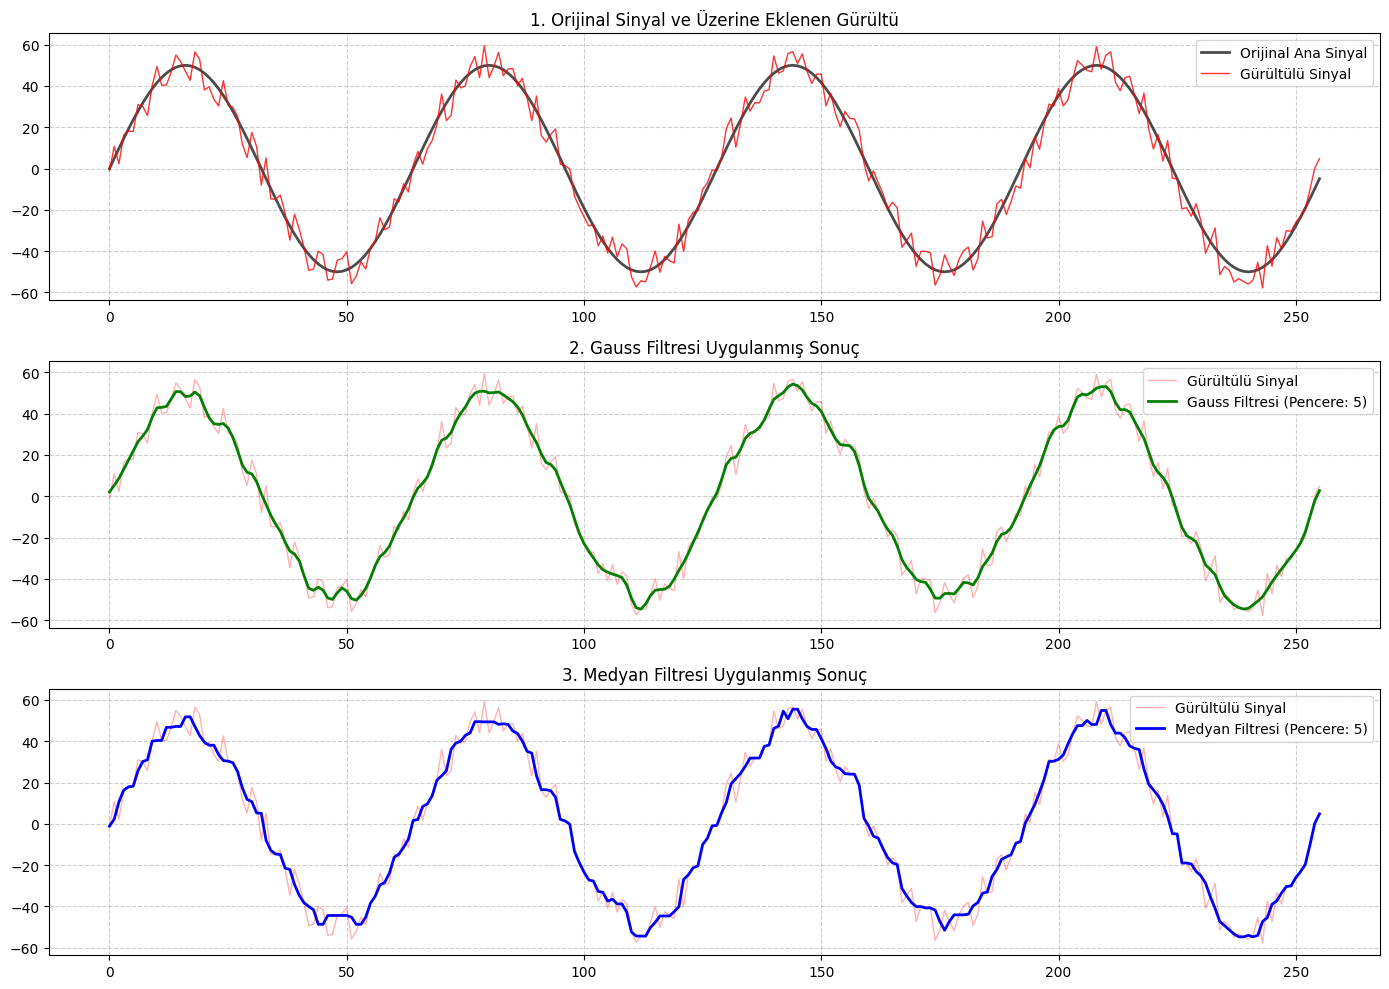

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('filtre_verisi.csv')

plt.figure(figsize=(14, 10))

# 1. Grafik: Orijinal ve Gürültülü
plt.subplot(3, 1, 1)
plt.plot(df['Index'], df['Original'], color='black', label='Orijinal Ana Sinyal', linewidth=2, alpha=0.7)
plt.plot(df['Index'], df['Noisy'], color='red', label='Gürültülü Sinyal', linewidth=1, alpha=0.8)
plt.title('1. Orijinal Sinyal ve Üzerine Eklenen Gürültü')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

# 2. Grafik: Gauss ile Temizleme
plt.subplot(3, 1, 2)
plt.plot(df['Index'], df['Noisy'], color='red', label='Gürültülü Sinyal', linewidth=1, alpha=0.3)
plt.plot(df['Index'], df['Gaussian'], color='green', label='Gauss Filtresi (Pencere: 5)', linewidth=2)
plt.title('2. Gauss Filtresi Uygulanmış Sonuç')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

# 3. Grafik: Medyan ile Temizleme
plt.subplot(3, 1, 3)
plt.plot(df['Index'], df['Noisy'], color='red', label='Gürültülü Sinyal', linewidth=1, alpha=0.3)
plt.plot(df['Index'], df['Median'], color='blue', label='Medyan Filtresi (Pencere: 5)', linewidth=2)
plt.title('3. Medyan Filtresi Uygulanmış Sonuç')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()